In [1]:
import numpy as np

def sample_source_positions(N):
    # sample from p(y)=2y
    u = np.random.uniform(0, 1, N)
    y = np.sqrt(u)
    return y

def sis_observables(y):
    # image positions
    x_plus = y + 1
    x_minus = y - 1

    # magnifications
    mu_plus = 1 + 1/y
    mu_minus = 1 - 1/y  # negative parity

    # absolute magnification of second image
    mu_minus_abs = np.abs(mu_minus)

    # time delay (dimensionless form)
    delta_t = 2 * y  # proportional; rescale later physically

    return mu_plus, mu_minus_abs, delta_t

def generate_dataset(N):
    y = sample_source_positions(N)
    mu_plus, mu_minus, delta_t = sis_observables(y)

    return {
        "y": y,
        "mu_plus": mu_plus,
        "mu_minus": mu_minus,
        "delta_t": delta_t
    }

# Example usage
data = generate_dataset(100000)

In [2]:
data["y"][:5], data["mu_plus"][:5], data["mu_minus"][:5], data["delta_t"][:5]

(array([0.98811512, 0.44950573, 0.9849316 , 0.5849606 , 0.79491773]),
 array([2.01202783, 3.22466573, 2.01529893, 2.70951685, 2.25799182]),
 array([0.01202783, 1.22466573, 0.01529893, 0.70951685, 0.25799182]),
 array([1.97623024, 0.89901147, 1.9698632 , 1.1699212 , 1.58983546]))

(array([1.79040645e-02, 1.29066725e-05, 4.84000221e-06, 1.97185275e-06,
        3.58518682e-07, 7.17037364e-07, 1.79259341e-07, 0.00000000e+00,
        3.58518682e-07, 5.37778023e-07]),
 array([  2.00000043,  57.78509897, 113.5701975 , 169.35529604,
        225.14039458, 280.92549312, 336.71059166, 392.4956902 ,
        448.28078874, 504.06588728, 559.85098582]),
 <BarContainer object of 10 artists>)

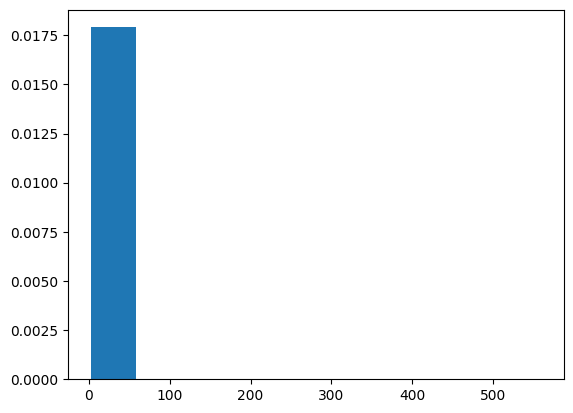

In [5]:
import matplotlib.pyplot as plt

mu = data["mu_plus"] + data["mu_minus"]
plt.hist(mu, bins=10, density=True)

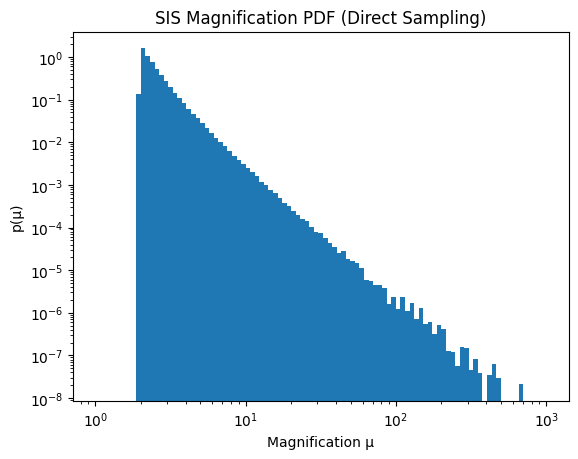

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def sample_sis_mu(N):
    u = np.random.rand(N)
    mu = 1.0 + 1.0 / np.sqrt(u)   # inverse CDF
    return mu

# Generate samples
mu_samples = sample_sis_mu(10**6)

# Plot
bins = np.logspace(0, 3, 100)
plt.hist(mu_samples, bins=bins, density=True)
plt.xscale('log')
plt.yscale('log')
plt.xlabel("Magnification μ")
plt.ylabel("p(μ)")
plt.title("SIS Magnification PDF (Direct Sampling)")
plt.show()

/work/sreekanth/miniconda3/envs/gwlens/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


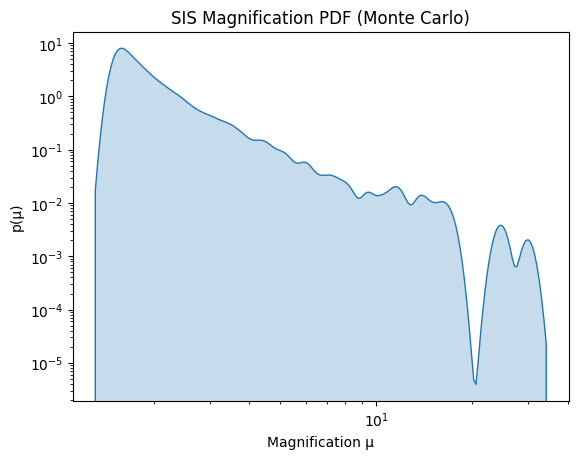

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# SIS magnification
def sis_magnification(beta, theta_E=1.0):
    return 1.0 + theta_E / np.abs(beta)

# Sample beta uniformly in a disk
def sample_beta(N, beta_max):
    u = np.random.rand(N)
    r = beta_max * np.sqrt(u)          # uniform in area
    phi = 2 * np.pi * np.random.rand(N)

    bx = r * np.cos(phi)
    by = r * np.sin(phi)

    beta = np.sqrt(bx**2 + by**2)
    return beta

# Main simulation
def simulate_sis(N=10000, theta_E=1.0, beta_max=2.0, beta_min=1e-6):
    beta = sample_beta(N, beta_max)

    # avoid divergence
    beta = np.clip(beta, beta_min, None)

    mu = sis_magnification(beta, theta_E)
    return mu

# Run
mu_samples = simulate_sis()

# Plot (log bins!)
bins = np.logspace(0, 3, 100)
sns.kdeplot(mu_samples, log_scale=True, fill=True)
#plt.hist(mu_samples, bins=bins, density=True)
plt.xscale('log')
plt.yscale('log')
plt.xlabel("Magnification μ")
plt.ylabel("p(μ)")
plt.title("SIS Magnification PDF (Monte Carlo)")
plt.show()

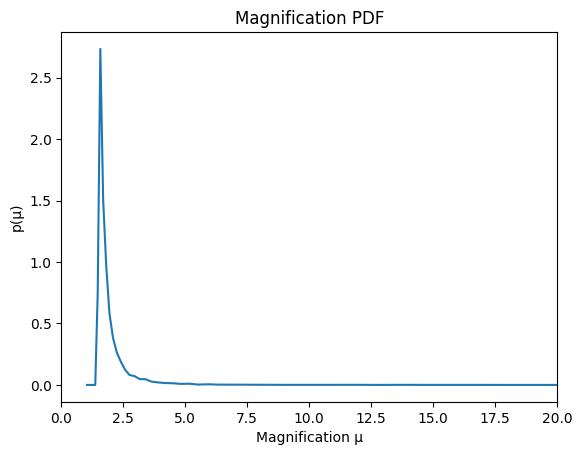

In [16]:
#log bins (IMPORTANT for lensing)
bins = np.logspace(0, 3, 100)

hist, edges = np.histogram(mu_samples, bins=bins, density=True)

# bin centers
centers = 0.5 * (edges[:-1] + edges[1:])

# plot
plt.plot(centers, hist)
#plt.xscale('log')
#plt.yscale('log')
plt.xlabel("Magnification μ")
plt.ylabel("p(μ)")
plt.xlim(0,20)
plt.title("Magnification PDF")
plt.show()

In [1]:
import numpy as np

def sample_sis_lens(
    N=10000,
    y_max=2.0,
    y_min=1e-3,
    sigma_v_range=(150, 300),   # km/s
    z_l=0.5,
    z_s=2.0,
    seed=None
):
    """
    Sample SIS lensing observables.

    Returns:
        dict with:
            y              : impact parameter
            mu1, mu2       : magnifications
            x1, x2         : image positions
            delta_t        : time delay (arbitrary units)
            sigma_v        : velocity dispersion
    """

    rng = np.random.default_rng(seed)

    # --- 1. Sample impact parameter (uniform in area → p(y) ∝ y)
    u = rng.random(N)
    y = np.sqrt(u) * y_max
    y = np.clip(y, y_min, None)

    # --- 2. Image positions
    x1 = y + 1.0
    x2 = y - 1.0   # negative side

    # --- 3. Magnifications
    mu1 = 1.0 + 1.0 / y
    mu2 = 1.0 - 1.0 / y

    # signed magnification for image 2 (can be negative parity)
    mu2_signed = mu2

    # absolute magnification (what you often use observationally)
    mu2_abs = np.abs(mu2)

    # --- 4. Fermat potential (dimensionless)
    def fermat(x, y):
        return 0.5 * (x - y)**2 - np.abs(x)

    phi1 = fermat(x1, y)
    phi2 = fermat(x2, y)

    delta_phi = phi1 - phi2   # dimensionless time delay

    # --- 5. Sample velocity dispersion
    sigma_v = rng.uniform(sigma_v_range[0], sigma_v_range[1], N)

    # --- 6. Physical scaling of time delay
    # Δt ∝ (σ_v^4) * Δφ   (SIS scaling)
    delta_t = (sigma_v / 200.0)**4 * delta_phi

    return {
        "y": y,
        "x1": x1,
        "x2": x2,
        "mu1": mu1,
        "mu2_signed": mu2_signed,
        "mu2_abs": mu2_abs,
        "delta_t": delta_t,
        "sigma_v": sigma_v
    }

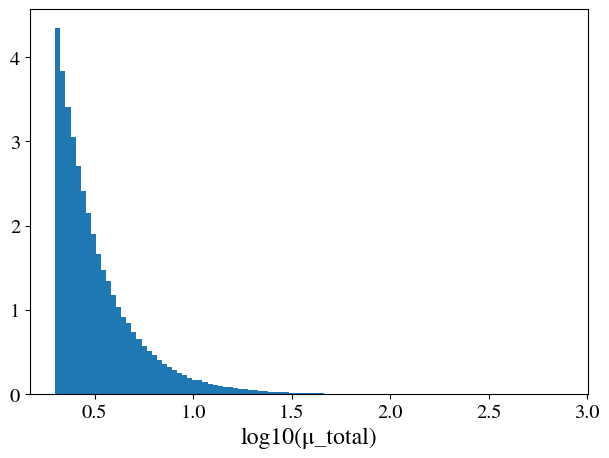

In [33]:
data = sample_sis_lens(N=1000000)
mask = data["y"]<1

mu_total = data["mu1"][mask] + data["mu2_abs"][mask]
mu_1 = data["mu1"][mask]
mu_2 = data["mu2_abs"][mask]


import matplotlib.pyplot as plt

plt.hist(np.log10(mu_total), bins=100, density=True)
plt.xlabel("log10(μ_total)")
plt.show()

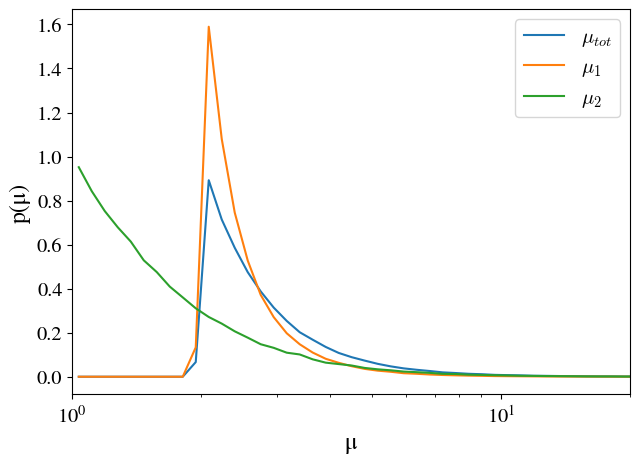

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from gwlens.tools import plotting
plotting.apply_figure_style()

mu1 = data["mu1"]

bins = np.logspace(0, 3, 100)
#bins =50
hist_mu, edges = np.histogram(mu_total, bins=bins, density=True)
centers_mu = 0.5 * (edges[:-1] + edges[1:])


hist_mu1, edges = np.histogram(mu_1, bins=bins, density=True)
centers_mu1 = 0.5 * (edges[:-1] + edges[1:])


hist_mu2, edges = np.histogram(mu_2, bins=bins, density=True)
centers_mu2 = 0.5 * (edges[:-1] + edges[1:])

mu = centers_mu
mu1 = centers_mu1
mu2 = centers_mu2


plt.plot(mu, hist_mu, label="$\\mu_{tot}$")
plt.plot(mu1, hist_mu1, label="$\\mu_{1}$")
plt.plot(mu2, hist_mu2, label="$\\mu_{2}$")
#plt.plot(mu, theory, '--')


#plt.plot(centers, hist_mu1, label="μ1")
plt.xscale('log')
#plt.yscale('log')
plt.xlabel("μ")
plt.xlim(1,20)
plt.ylabel("p(μ)")
plt.legend()
plt.show()

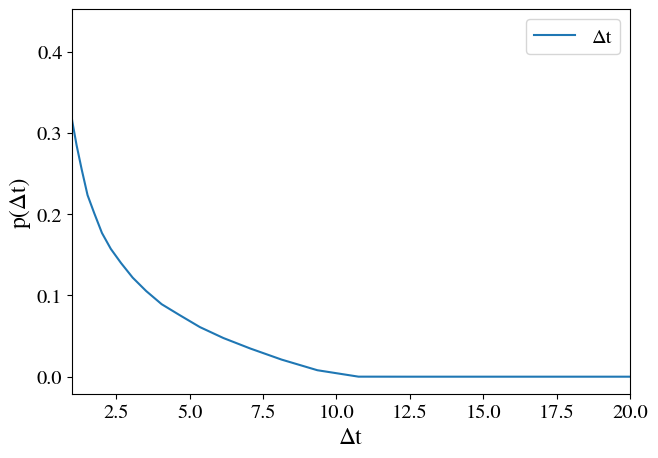

In [39]:
delta_t = np.abs(data["delta_t"][mask])   # ensure positive

bins_t = np.logspace(-3, 3, 100)

hist_dt, edges_t = np.histogram(delta_t, bins=bins_t, density=True)
centers_t = 0.5 * (edges_t[:-1] + edges_t[1:])

plt.plot(centers_t, hist_dt, label="Δt")
#plt.xscale('log')
#plt.yscale('log')
plt.xlabel("Δt")
plt.xlim(1,20)
plt.ylabel("p(Δt)")
plt.legend()
plt.show()